# 05: Asymmetric cost and uncertainty

Study level 5. Notebook 04 left a working model, LightGBM on 40 window features, at RMSE 12.4 and PHM08 230 per 100 predictions, trained with squared error and evaluated with an asymmetric score. This notebook asks whether that incoherence costs anything, what the model can say about its own uncertainty, and what the decision layer needs from it.

Questions, each answered by one section and collected in the Decisions cell at the end:

1. Where does the working model's PHM08 score come from: bias, or a few large errors?
2. Can the model predict quantiles of remaining life, and are they calibrated?
3. Which quantile does the scenario's cost ask for, and is the per-prediction cost well posed?
4. Does training with an asymmetric loss improve PHM08?
5. Can the quantiles be corrected into an honest interval?
6. What does the pipeline carry into the decision layer?

Same protocol as notebooks 03 and 04: engine-wise folds, cut points, RMSE and PHM08 per 100, means over 30 draws. Theory in `docs/learning/05-asymmetric-losses.md`.

## 1. Where the score comes from

The working model, retrained here out-of-fold with a fixed 1,200 trees (notebook 04 showed early stopping changes nothing at this learning rate). The question is whether PHM08 can be improved by shifting predictions, which would mean the problem is bias, or not, which would mean it sits in the tails.

In [1]:
import os
import time

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")  # silence the hint MLflow prints on import

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from turbofan_rul.config import FD001_PRUNED_FEATURES as FEATURES
from turbofan_rul.config import LGBM_PARAMS, N_FOLDS, RUL_CAP
from turbofan_rul.data_loading import add_rul_labels, load_subset
from turbofan_rul.evaluation import maintenance_cost, phm08_per_100, summarize
from turbofan_rul.features import build_features
from turbofan_rul.validation import engine_folds, sample_cut_points

df = add_rul_labels(load_subset("FD001", split="train"))
folds = engine_folds(df)
df["fold"] = df["unit"].map(folds)
lifetimes = df.groupby("unit")["cycle"].max()
X = build_features(df)
X["rul_true"] = lifetimes.loc[X["unit"]].to_numpy() - X["cycle"].to_numpy()  # uncapped
rows = X[["unit", "cycle", "fold", "rul", "rul_true"]].copy()

PARAMS = {**LGBM_PARAMS, "n_estimators": 1200}
CUTS = [sample_cut_points(df, seed=s) for s in range(30)]


def oof_rows(target="rul", start_from_mean=False, **overrides):
    # Row-level out-of-fold predictions of a LightGBM with the given objective overrides.
    # A custom objective starts from zero; `start_from_mean` gives it the label mean as init score,
    # the same start the built-in objectives get from boost_from_average.
    pred = np.full(len(X), np.nan)
    for f in range(N_FOLDS):
        train, hold = X[X["fold"] != f], (X["fold"] == f).to_numpy()
        model = lgb.LGBMRegressor(**{**PARAMS, **overrides})
        if start_from_mean:
            m = float(train[target].mean())
            model.fit(train[FEATURES], train[target], init_score=np.full(len(train), m))
            pred[hold] = model.predict(X.loc[hold, FEATURES]) + m
        else:
            model.fit(train[FEATURES], train[target])
            pred[hold] = model.predict(X.loc[hold, FEATURES])
    return pred


def at_cuts(pred, seed=0, **extra):
    # Join row-level predictions to the cut points of one draw.
    return CUTS[seed].merge(rows.assign(pred=pred, **extra), on=["unit", "cycle"], suffixes=("", "_row"))


def score_draws(pred):
    # Mean over 30 draws of RMSE, PHM08 per 100 and mean error, plus per-fold RMSE on draw 0.
    draws = pd.DataFrame([summarize(c["rul_true"], c["pred"]) for c in (at_cuts(pred, s) for s in range(30))])
    c0 = at_cuts(pred)
    per_fold = c0.groupby("fold").apply(lambda g: summarize(g["rul_true"], g["pred"])["rmse"], include_groups=False)
    return {"rmse": draws["rmse"].mean(), "phm08_per_100": draws["phm08_per_100"].mean(),
            "mean_error": draws["mean_error"].mean(), "late_share": np.mean([(c["pred"] > c["rul_true"]).mean() for c in (at_cuts(pred, s) for s in range(30))]),
            "fold_min": per_fold.min(), "fold_max": per_fold.max()}


t0 = time.perf_counter()
pred_l2 = np.clip(oof_rows(), 0, RUL_CAP)
print(f"working model refitted out-of-fold in {time.perf_counter() - t0:.0f} s")
results = pd.DataFrame({"squared error (working model)": score_draws(pred_l2)}).T
results.round(1)

working model refitted out-of-fold in 17 s


,rmse,phm08_per_100,mean_error,late_share,fold_min,fold_max
squared error (working model),12.2,223.2,-0.9,0.5,10.5,12.6


In [2]:
# PHM08 by error size and direction, and the PHM08-optimal constant shift
c0 = at_cuts(pred_l2)
d = c0["pred"] - c0["rul_true"]
penalty = np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)
size = pd.cut(d.abs(), [-0.1, 5, 10, 20, 30, 200], labels=["0 to 5", "5 to 10", "10 to 20", "20 to 30", "over 30"])
breakdown = pd.DataFrame({"cuts": pd.Series(penalty).groupby([size, np.where(d > 0, "late", "early")], observed=True).size(),
                          "share of PHM08": pd.Series(penalty).groupby([size, np.where(d > 0, "late", "early")], observed=True).sum() / penalty.sum()})
print(breakdown.round(2).to_string())

shifts = np.arange(-15, 6, 1)
shift_scores = pd.DataFrame({sh: {"rmse": np.mean([summarize(c["rul_true"], np.clip(c["pred"] + sh, 0, RUL_CAP))["rmse"] for c in (at_cuts(pred_l2, s) for s in range(10))]),
                                  "phm08_per_100": np.mean([phm08_per_100(c["rul_true"], np.clip(c["pred"] + sh, 0, RUL_CAP)) for c in (at_cuts(pred_l2, s) for s in range(10))])}
                             for sh in shifts}).T
best_shift = shift_scores["phm08_per_100"].idxmin()
print(f"\nPHM08-optimal constant shift: {best_shift:+d} cycles")
shift_scores.loc[[-15, -10, -5, -2, 0, 2, 5]].round(1)

                cuts  share of PHM08
0 to 5   early   237            0.02
         late    258            0.03
5 to 10  early   106            0.04
         late    115            0.06
10 to 20 early    84            0.08
         late     81            0.13
20 to 30 early    59            0.16
         late     36            0.18
over 30  early    13            0.08
         late     11            0.23



PHM08-optimal constant shift: -2 cycles


,rmse,phm08_per_100
-15,19.5,460.2
-10,16.0,308.9
-5,13.3,225.8
-2,12.3,208.9
0,12.0,213.8
2,12.1,231.7
5,12.7,282.0


**Reading.** The working model's mean error is −0.9 cycles and half of its errors are late: it sits where squared error puts it, at the centre. The breakdown says where the score lives. Errors above 30 cycles are 24 of the 1,000 cuts, 2.4%, and carry 31% of the PHM08 score; late errors above 20 cycles are 47 cuts and carry 41%. The 495 cuts within 5 cycles carry 5%.

Shifting every prediction by a constant confirms it: the PHM08-optimal shift is −2 cycles, worth about 5 points of a score of 214, inside the draw noise. Shifting further makes things worse quickly, because every well-predicted engine becomes an early error that PHM08 also charges. The score is not a bias problem. It is a tail problem, and the tail is a few dozen engines.

## 2. Quantile models

The same LightGBM with `objective="quantile"` at five levels. Two decisions are tested here rather than assumed. First, `boost_from_average=False`: with 39% of training labels at the cap, the 0.75 quantile of the label is exactly 125 and a model started there never moves (level 5, 5.3). Second, the label: quantiles trained on the capped label can never predict above 125, which puts 11% of the cut points outside any interval by construction. Both labels are tried.

Coverage is the number to read: the share of true remaining lives at or below the predicted quantile, which should equal the quantile level.

In [3]:
ALPHAS = [0.1, 0.25, 0.5, 0.75, 0.9]
quantile_preds = {}
for label in ["rul", "rul_true"]:
    for a in ALPHAS:
        quantile_preds[(label, a)] = oof_rows(target=label, objective="quantile", alpha=a, boost_from_average=False)

# the collapse, reproduced once with the default start
collapsed = oof_rows(target="rul", objective="quantile", alpha=0.75)
print(f"quantile 0.75 with boost_from_average=True: {np.unique(np.round(collapsed, 3)).size} distinct predicted values, mean {collapsed.mean():.1f}")

coverage = []
for (label, a), p in quantile_preds.items():
    cs = [at_cuts(np.clip(p, 0, None), s) for s in range(30)]
    coverage.append({"label": "capped" if label == "rul" else "uncapped", "alpha": a,
                     "P(true <= quantile)": np.mean([(c["rul_true"] <= c["pred"]).mean() for c in cs]),
                     "rmse": np.mean([summarize(c["rul_true"], np.clip(c["pred"], 0, RUL_CAP))["rmse"] for c in cs]),
                     "phm08_per_100": np.mean([phm08_per_100(c["rul_true"], np.clip(c["pred"], 0, RUL_CAP)) for c in cs]),
                     "mean prediction": np.mean([c["pred"].mean() for c in cs])})
coverage = pd.DataFrame(coverage).set_index(["label", "alpha"])
coverage.round(2)

quantile 0.75 with boost_from_average=True: 1 distinct predicted values, mean 125.0


P(true <= quantile)   rmse  phm08_per_100  mean prediction
label    alpha                                                            
capped   0.10                  0.25  16.34         356.72            63.94
         0.25                  0.36  13.25         236.39            68.17
         0.50                  0.50  12.44         256.08            72.27
         0.75                  0.64  14.19         472.83            76.28
         0.90                  0.75  17.00         957.66            80.17
uncapped 0.10                  0.27  15.86         339.40            65.43
         0.25                  0.43  12.58         234.46            71.53
         0.50                  0.60  12.50         293.45            77.87
         0.75                  0.73  13.93         458.05            84.87
         0.90                  0.85  16.26         803.66            92.89

In [4]:
# Crossing between separately trained quantiles, on draw 0
for label in ["rul", "rul_true"]:
    c = at_cuts(quantile_preds[(label, 0.1)], lo=quantile_preds[(label, 0.1)], mid=quantile_preds[(label, 0.5)], hi=quantile_preds[(label, 0.9)])
    print(f"{'capped' if label == 'rul' else 'uncapped'} label: q10 > q90 on {(c['lo'] > c['hi']).mean():.1%} of cuts, q10 > q50 on {(c['lo'] > c['mid']).mean():.1%}")

capped label: q10 > q90 on 1.4% of cuts, q10 > q50 on 9.3%
uncapped label: q10 > q90 on 1.9% of cuts, q10 > q50 on 8.9%


**Reading.** Three things, in order of consequence.

- **The collapse is real and cheap to avoid.** With LightGBM's default start, the 0.75-quantile model predicts a single value, 125, for every row. With `boost_from_average=False` the same objective trains normally. A pipeline that retrains quantile models needs this flag and a check that predictions are not constant.
- **The quantiles are pulled toward the centre.** On the capped label, the 0.1 quantile leaves 25% of outcomes below it instead of 10%, and the 0.9 leaves 75% instead of 90%. The model's spread is about half of what it should be: the 0.1-to-0.9 interval covers 50% of outcomes, not 80%. Section 5 corrects this.
- **The uncapped label fixes the upper end.** Trained on the true remaining life, the 0.9 quantile reaches 85% instead of 75%, because it can predict above 125; the lower quantiles barely change. The median trained uncapped is biased up (60% below it), as expected for a label whose upper part was uncapped. So the point prediction stays on the capped label, and the interval's quantiles are trained on the uncapped one.

Crossing is modest, 1.4 to 1.9% of cuts with the 0.1 quantile above the 0.9, and is removed by sorting per row.

## 3. Which quantile does the cost ask for?

The newsvendor rule: with linear costs $c_u$ for predicting too little and $c_o$ for too much, the best prediction is the quantile $c_u / (c_u + c_o)$. The README scenario sketches a flat failure cost of 10 shop visits and a wasted-cycle cost of 1/200 of a visit. Applied per prediction, that ratio is close to zero. The cell checks what the per-prediction cost actually rewards.

In [5]:
c0 = at_cuts(pred_l2)
candidates = {
    "predict zero always": np.zeros(len(c0)),
    "truth minus 10 cycles": np.clip(c0["rul_true"] - 10, 0, None),
    "quantile 0.1 (capped label)": at_cuts(np.clip(quantile_preds[("rul", 0.1)], 0, RUL_CAP))["pred"],
    "squared error (working model)": c0["pred"],
    "quantile 0.9 (capped label)": at_cuts(np.clip(quantile_preds[("rul", 0.9)], 0, RUL_CAP))["pred"],
}
newsvendor = pd.DataFrame({name: {"scenario cost per 100": 100 * maintenance_cost(c0["rul_true"], p, cost_late=10, cost_early_per_cycle=1 / 200) / len(c0),
                                  "PHM08 per 100": phm08_per_100(c0["rul_true"], p)} for name, p in candidates.items()}).T
newsvendor.round(1)

,scenario cost per 100,PHM08 per 100
predict zero always,35.0,643012.4
truth minus 10 cycles,4.8,110.9
quantile 0.1 (capped label),255.6,312.1
squared error (working model),503.2,210.8
quantile 0.9 (capped label),756.0,856.3


**Reading.** Predicting zero for every engine costs 35 per 100 predictions under the sketched cost; the working model costs 503 and the best quantile model 256. The sketch rewards being early without limit, because an early error costs at most 125/200 = 0.6 visits while a late one costs 10, and the rule says to predict near the floor of every distribution. That is not what a planner would do, and the reason is what the sketch leaves out: the shop visit itself, and the capacity that makes visits scarce. Those costs enter at the decision level, where acting on one engine takes a slot from another. The conclusion for this notebook: the per-prediction cost is not the objective to train against, and the asymmetry belongs in the decision, with the model supplying a calibrated distribution.

## 4. Asymmetric training losses

PHM08 cannot be used as a training loss (its gradient explodes on the late side), so the surrogate is squared error with a weight $w$ on late residuals, as a custom LightGBM objective returning gradient and Hessian per row. With $w = 1$ it must reproduce squared error exactly; that check runs first.

In [6]:
def asymmetric_squared(w_late):
    # Custom objective: w * d^2 for late residuals (pred > true), d^2 otherwise.
    def objective(y_true, y_pred):
        d = y_pred - y_true
        w = np.where(d > 0, w_late, 1.0)
        return 2 * w * d, 2 * w
    return objective


# Sanity check: w = 1 must match the built-in squared error on one fold, given the same starting point.
# Both start from the training-label mean (init_score), with no row or column subsampling so the trees are deterministic.
train0, hold0 = X[X["fold"] != 0], X[X["fold"] == 0]
m0 = float(train0["rul"].mean())
check_params = {**PARAMS, "n_estimators": 200, "subsample": 1.0, "colsample_bytree": 1.0, "boost_from_average": False}
builtin = lgb.LGBMRegressor(**check_params).fit(train0[FEATURES], train0["rul"], init_score=np.full(len(train0), m0)).predict(hold0[FEATURES])
custom = lgb.LGBMRegressor(**{**check_params, "objective": asymmetric_squared(1.0)}).fit(train0[FEATURES], train0["rul"], init_score=np.full(len(train0), m0)).predict(hold0[FEATURES])
print(f"max |custom - builtin| over {len(hold0):,} rows: {np.abs(custom - builtin).max():.4f} cycles")
assert np.abs(custom - builtin).max() < 1e-3, "the custom objective at w = 1 must reproduce squared error"

asym_preds = {}
for w in [2, 4, 8]:
    p = oof_rows(objective=asymmetric_squared(float(w)), start_from_mean=True)
    asym_preds[w] = np.clip(p, 0, RUL_CAP)
    results.loc[f"asymmetric squared, late x{w}"] = score_draws(asym_preds[w])
results.loc["quantile 0.25 (capped label)"] = score_draws(np.clip(quantile_preds[("rul", 0.25)], 0, RUL_CAP))
results.round(1)

max |custom - builtin| over 4,148 rows: 0.0000 cycles


,rmse,phm08_per_100,mean_error,late_share,fold_min,fold_max
squared error (working model),12.2,223.2,-0.9,0.5,10.5,12.6
"asymmetric squared, late x2",12.3,215.9,-1.9,0.5,10.7,12.8
"asymmetric squared, late x4",12.7,222.3,-2.9,0.4,10.7,13.2
"asymmetric squared, late x8",13.0,225.7,-3.9,0.4,10.8,13.4
quantile 0.25 (capped label),13.3,236.4,-4.2,0.4,9.9,13.9


In [7]:
# Error mix on draw 0: how many large errors on each side, and the worst late one
mix = {}
for name, p in [("squared error", pred_l2), ("asymmetric x4", asym_preds[4]), ("asymmetric x8", asym_preds[8]), ("quantile 0.25", np.clip(quantile_preds[("rul", 0.25)], 0, RUL_CAP))]:
    c = at_cuts(p)
    d = c["pred"] - c["rul_true"]
    mix[name] = {"late > 20": int((d > 20).sum()), "early > 20": int((d < -20).sum()), "worst late": d.max(), "worst early": -d.min()}
pd.DataFrame(mix).T.round(0).astype(int)

,late > 20,early > 20,worst late,worst early
squared error,47,72,46,46
asymmetric x4,36,83,45,55
asymmetric x8,28,90,43,53
quantile 0.25,30,97,44,56


**Reading.** The custom objective reproduces squared error exactly at $w = 1$ once both start from the same point, which is the check that makes the rest trustworthy. With the late side weighted 2, 4 and 8 times, PHM08 moves to 216, 222 and 226 against 223 for squared error: inside the draw noise, in both directions. The quantile 0.25 model is worse (236).

What the weight does change is the error mix. With $w = 8$, late errors above 20 cycles fall from 47 to 28 and early errors above 20 rise from 72 to 90; the worst late error stays at 43 to 46 cycles whatever the loss. The model trades late errors for early ones at a rate PHM08 considers neutral, and the few huge errors that carry the score do not move, because they belong to engines whose degradation the features do not yet see (notebook 04, section 5). Reweighting the loss gives the trees no new information about those engines. The asymmetric losses are recorded as tried and not adopted, and the point model stays on squared error.

## 5. Calibrated intervals

Split conformal, inside each fold: 16 of the 80 training engines are held out, the quantile models are fitted on the other 64, and the residuals on the held-out engines' cut points give the shift that restores nominal coverage (`conformal_offset` in `src/turbofan_rul/uncertainty.py`). Quantiles are trained on the uncapped label (section 2) and sorted per row. Coverage is then checked on the validation engines, overall and by remaining-life band.

In [8]:
from turbofan_rul.uncertainty import conformal_offset, sort_quantiles

LO, HI = 0.1, 0.9


def oof_quantile_pair(calibrate):
    lo, hi, shifts = np.full(len(X), np.nan), np.full(len(X), np.nan), []
    for f in range(N_FOLDS):
        train, hold = X[X["fold"] != f], (X["fold"] == f).to_numpy()
        if calibrate:
            cal_units = np.random.default_rng(f).choice(train["unit"].unique(), size=16, replace=False)
            fit, cal = train[~train["unit"].isin(cal_units)], train[train["unit"].isin(cal_units)]
        else:
            fit, cal = train, None
        models = {a: lgb.LGBMRegressor(**{**PARAMS, "objective": "quantile", "alpha": a, "boost_from_average": False}).fit(fit[FEATURES], fit["rul_true"]) for a in (LO, HI)}
        p_lo, p_hi = models[LO].predict(X.loc[hold, FEATURES]), models[HI].predict(X.loc[hold, FEATURES])
        if calibrate:
            cal_cuts = CUTS[0][CUTS[0]["unit"].isin(cal_units)].merge(cal[["unit", "cycle", "rul_true"] + FEATURES], on=["unit", "cycle"], suffixes=("_cut", ""))
            s_lo = conformal_offset(cal_cuts["rul_true"], models[LO].predict(cal_cuts[FEATURES]), LO)
            s_hi = conformal_offset(cal_cuts["rul_true"], models[HI].predict(cal_cuts[FEATURES]), HI)
            p_lo, p_hi = p_lo + s_lo, p_hi + s_hi
            shifts.append((round(s_lo, 1), round(s_hi, 1)))
        lo[hold], hi[hold] = sort_quantiles(p_lo, p_hi)
    return np.clip(lo, 0, None), np.clip(hi, 0, None), shifts


raw_lo, raw_hi, _ = oof_quantile_pair(calibrate=False)
cal_lo, cal_hi, shifts = oof_quantile_pair(calibrate=True)
print("conformal shifts per fold (lower, upper):", shifts)

band = lambda c: pd.cut(c["rul_true"], [0, 25, 50, 75, 100, 125, 150])
interval = {}
for name, lo, hi in [("raw", raw_lo, raw_hi), ("conformal", cal_lo, cal_hi)]:
    cs = [at_cuts(pred_l2, s, lo=lo, hi=hi) for s in range(30)]
    inside = lambda c: (c["rul_true"] >= c["lo"]) & (c["rul_true"] <= c["hi"])
    interval[(name, "coverage")] = pd.concat([inside(c).groupby(band(c), observed=True).mean() for c in cs], axis=1).mean(axis=1)
    interval[(name, "width")] = pd.concat([(c["hi"] - c["lo"]).groupby(band(c), observed=True).mean() for c in cs], axis=1).mean(axis=1)
    print(f"{name:10s} overall coverage {np.mean([inside(c).mean() for c in cs]):.3f}, mean width {np.mean([(c['hi'] - c['lo']).mean() for c in cs]):.1f} cycles")
pd.DataFrame(interval).round(2)

conformal shifts per fold (lower, upper): [(-11.4, 0.9), (-5.3, 0.9), (-5.0, 1.2), (-3.0, 2.0), (-0.8, 3.6)]
raw        overall coverage 0.585, mean width 27.5 cycles
conformal  overall coverage 0.728, mean width 33.7 cycles


raw        conformal       
           coverage  width  coverage  width
rul_true                                   
(0, 25]        0.55   4.99      0.85  10.61
(25, 50]       0.54   8.15      0.76  14.24
(50, 75]       0.52  17.44      0.66  24.32
(75, 100]      0.54  34.06      0.63  41.16
(100, 125]     0.64  49.54      0.70  55.55
(125, 150]     0.77  60.26      0.77  65.39

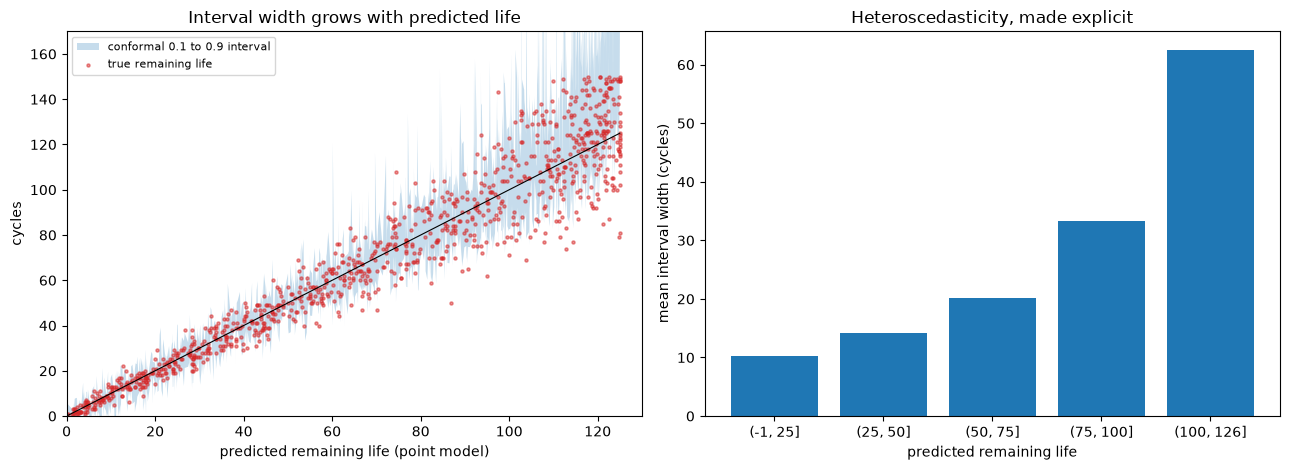

In [9]:
c = at_cuts(pred_l2, 0, lo=cal_lo, hi=cal_hi).sort_values("pred")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].fill_between(c["pred"], c["lo"], c["hi"], alpha=0.25, label="conformal 0.1 to 0.9 interval")
axes[0].scatter(c["pred"], c["rul_true"], s=5, alpha=0.5, color="C3", label="true remaining life")
axes[0].plot([0, 125], [0, 125], color="k", lw=0.8)
axes[0].set(xlabel="predicted remaining life (point model)", ylabel="cycles", title="Interval width grows with predicted life", xlim=(0, 130), ylim=(0, 170))
axes[0].legend(fontsize=8, loc="upper left")
by_pred = pd.cut(c["pred"], [-1, 25, 50, 75, 100, 126])
width_by_pred = (c["hi"] - c["lo"]).groupby(by_pred, observed=True).mean()
axes[1].bar([str(b) for b in width_by_pred.index], width_by_pred.values)
axes[1].set(xlabel="predicted remaining life", ylabel="mean interval width (cycles)", title="Heteroscedasticity, made explicit")
plt.tight_layout()
plt.show()

**Reading.** The raw 0.1-to-0.9 interval covers 58% of outcomes instead of 80% (the uncapped label already helps: it was 48% with capped quantiles in the study-sheet check). The conformal shift raises it to 73%, with the lower end moved down by 1 to 11 cycles depending on the fold and the upper end up by 1 to 4. The shifts vary a lot across folds because 16 calibration engines give a noisy estimate; pooling residuals across folds is the obvious next step and is left as an open question.

Coverage is not uniform. After calibration it is 85% in the last 25 cycles and 76% from 25 to 50, the bands where decisions are made, but 63 to 66% between 50 and 100, where the model's errors are largest and a constant shift is too small. A scaled correction (conformalized quantile regression) would widen the middle without widening the ends.

The interval width is the heteroscedasticity from level 2, finally stated per engine: about 10 cycles when the model predicts under 25 cycles, 20 at 50 to 75, over 60 above 100. An engine predicted at 20 cycles is a precise statement; one predicted at 110 is a loose one. That difference is what the decision layer needs, and no point prediction carries it.

## 6. What the pipeline carries

Per engine, at every scoring: the point prediction from the squared-error model on the capped label, a conformal 0.1-to-0.9 interval from quantile models on the uncapped label, and the age. The SHAP explanation from notebook 04 is added at scoring time. The table below is the output format, shown for a few validation cuts, and the runs are logged next to the notebook 04 models.

In [10]:
output = at_cuts(pred_l2, 0, lo=cal_lo, hi=cal_hi)[["unit", "cycle", "pred", "lo", "hi", "rul_true"]].rename(
    columns={"cycle": "age", "pred": "rul_point", "lo": "rul_q10", "hi": "rul_q90"})
output["interval_width"] = output["rul_q90"] - output["rul_q10"]
output.sample(8, random_state=1).sort_values("rul_point").round(0).astype(int)

,unit,age,rul_point,rul_q10,rul_q90,rul_true,interval_width
929,93,139,22,8,31,16,23
368,37,130,40,27,49,40,23
507,51,172,43,40,57,41,16
818,82,168,54,33,54,46,20
452,46,148,97,86,124,108,38
242,25,116,99,90,121,114,31
262,27,71,121,104,195,85,91
810,82,89,121,114,173,125,59


In [11]:
import mlflow

from turbofan_rul.tracking import log_model_run, start_experiment

start_experiment("fd001-development")
common = {"model": "LightGBM", "features": "window:40 (FD001_PRUNED_FEATURES)", "prediction_clip": "0-125", **PARAMS}
logged = {
    "lgbm-40-asymmetric-x4": (asym_preds[4], {**common, "objective": "asymmetric_squared", "late_weight": 4}),
    "lgbm-40-quantile-0.25": (np.clip(quantile_preds[("rul", 0.25)], 0, RUL_CAP), {**common, "objective": "quantile", "alpha": 0.25, "boost_from_average": False}),
}
for run_name, (pred, params) in logged.items():
    sc = score_draws(pred)
    log_model_run(run_name, params, {"rmse_mean": sc["rmse"], "phm08_per_100_mean": sc["phm08_per_100"], "mean_error": sc["mean_error"],
                                     "fold_rmse_min": sc["fold_min"], "fold_rmse_max": sc["fold_max"], "n_draws": 30},
                  predictions=rows[["unit", "cycle", "fold", "rul_true"]].assign(pred=pred), tags={"notebook": "05_asymmetric_cost", "adopted": "no"})
cov = np.mean([((c["rul_true"] >= c["lo"]) & (c["rul_true"] <= c["hi"])).mean() for c in (at_cuts(pred_l2, s, lo=cal_lo, hi=cal_hi) for s in range(30))])
log_model_run("lgbm-40-interval-q10-q90-conformal", {**common, "objective": "quantile", "alphas": "0.1,0.9", "label": "uncapped", "calibration": "split conformal, 16 engines per fold"},
              {"coverage_mean": cov, "width_mean": float(np.mean(cal_hi - cal_lo)), "n_draws": 30},
              predictions=rows[["unit", "cycle", "fold", "rul_true"]].assign(q10=cal_lo, q90=cal_hi), tags={"notebook": "05_asymmetric_cost", "adopted": "yes"})
runs = mlflow.search_runs(experiment_names=["fd001-development"])
runs[["tags.mlflow.runName", "metrics.rmse_mean", "metrics.phm08_per_100_mean", "metrics.coverage_mean", "tags.adopted"]].sort_values("metrics.rmse_mean").round(2)

/Users/alexmunozestornell/Documents/Personal_Projects/turbofan-rul/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,tags.mlflow.runName,metrics.rmse_mean,metrics.phm08_per_100_mean,metrics.coverage_mean,tags.adopted
3,lgbm-40-features,12.42,229.66,NaN,NaN
4,lgbm-99-features,12.68,238.77,NaN,NaN
2,lgbm-40-asymmetric-x4,12.73,222.27,NaN,no
1,lgbm-40-quantile-0.25,13.25,236.39,NaN,no
5,linear-99-features,19.30,659.66,NaN,NaN
6,linear-12-sensors,25.05,1708.93,NaN,NaN
7,clock-weibull3-capped,32.01,7358.59,NaN,NaN
0,lgbm-40-interval-q10-q90-conformal,NaN,NaN,0.73,yes


**Reading.** Each scored engine leaves with four numbers the planner can use: its age, the point prediction, and a calibrated lower and upper bound. The sample rows show the range: unit 93 at 22 cycles with an interval of 23, unit 27 at 121 with an interval of 91. The planner should treat those two very differently, and section 5 is what licenses the difference. The MLflow experiment now records the interval model as adopted and the two asymmetric point models as tried and not adopted, with their scores, so the choice is reproducible and reviewable.

---

## Decisions

| # | Question | Decision | Evidence |
|---|----------|----------|----------|
| 1 | Where the PHM08 score comes from | A few large errors, not bias. The PHM08-optimal constant shift is −2 cycles, worth about 5 points of 214 | Section 1: 2.4% of cuts with errors over 30 cycles carry 31% of the score |
| 2 | Training loss for the point model | Squared error on the capped label, unchanged from notebook 04. Asymmetric squared losses (late weight 2, 4, 8) and the quantile 0.25 model were tried and not adopted | Section 4: PHM08 216 to 236 vs 223, inside noise; the worst late error stays at 43 to 46 cycles under every loss |
| 3 | Quantile models | LightGBM quantile objectives with `boost_from_average=False`, trained on the uncapped label, sorted per row | Section 2: the default start collapses the 0.75 model to a constant 125; the uncapped label lifts the 0.9 quantile's coverage from 75% to 85%; crossing 1.4 to 1.9% before sorting |
| 4 | Interval and calibration | 0.1-to-0.9 interval, split-conformal shift per quantile on 16 held-out engines per fold (`uncertainty.conformal_offset`). Coverage 73% overall, 76 to 85% below 50 cycles | Section 5: raw coverage 58%; shifts −11 to −1 (lower) and +1 to +4 (upper); middle band still 63 to 66% |
| 5 | The scenario's per-prediction cost | Not used as a training or selection objective. It is degenerate without the shop-visit cost and the capacity limit, which enter at the decision level (level 7) | Section 3: "predict zero always" costs 35 per 100 vs 503 for the working model |
| 6 | Per-engine output for the planner | Age, point prediction (capped), calibrated 0.1 and 0.9 bounds (uncapped), plus the SHAP explanation at scoring time | Section 6 |

Notes to carry into notebook 06 (maintenance planning):

- The interval, not the point, is the input to the decision. The decision rule with a failure cost of 10 and a visit cost of 1 is to act when P(fail before the next slot) exceeds about 1/11; with capacity, the threshold becomes a shadow price set by the other engines that week.
- Coverage is honest only below about 50 cycles of remaining life (76 to 85%). For engines further out, the interval understates uncertainty; the planner should not make irreversible decisions on those.
- A constant-per-engine probability of failure before week $w$ can be read off the interval by interpolation; a calibrated CDF would be better, and needs more quantile levels or a distributional model. Open question for level 7.
- Pooling conformal residuals across folds, and a scaled (CQR) correction for the middle band, are the two improvements with the most expected value, in that order.
- The quantile models need two guards in the pipeline: `boost_from_average=False`, and a check that predictions are not constant.